## Setup

In [1]:
!nvidia-smi

Mon Jul 29 18:24:34 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   30C    P0              44W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
print("HOME:", HOME)

HOME: /content


### Install dependencies

In [3]:
!pip install -q git+https://github.com/huggingface/transformers.git
!pip install -q git+https://github.com/roboflow/supervision.git
!pip install -q accelerate
!pip install -q roboflow
!pip install -q torchmetrics
!pip install -q "albumentations>=1.4.5"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.7/178.7 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 868.8/868.8 kB 40.4 MB/s eta 0:00:00


### Imports

In [4]:
import torch
import requests

import numpy as np
import supervision as sv
import albumentations as A

from PIL import Image
from pprint import pprint
from roboflow import Roboflow
from dataclasses import dataclass, replace
from google.colab import userdata
from torch.utils.data import Dataset
from transformers import (
    AutoImageProcessor,
    AutoModelForObjectDetection,
    TrainingArguments,
    Trainer
)
from torchmetrics.detection.mean_ap import MeanAveragePrecision

## Inference with pre-trained RT-DETR model

In [5]:
# @title Load model

CHECKPOINT = "PekingU/rtdetr_r50vd_coco_o365"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForObjectDetection.from_pretrained(CHECKPOINT).to(DEVICE)
processor = AutoImageProcessor.from_pretrained(CHECKPOINT)


The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.


config.json:   0%|          | 0.00/5.11k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/172M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

In [6]:
# @title Run inference

URL = "https://media.roboflow.com/notebooks/examples/dog.jpeg"

image = Image.open(requests.get(URL, stream=True).raw)
inputs = processor(image, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    outputs = model(**inputs)

w, h = image.size
results = processor.post_process_object_detection(
    outputs, target_sizes=[(h, w)], threshold=0.3)

## Fine-tune RT-DETR on custom dataset

In [8]:
# @title Download dataset from Roboflow Universe

# ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
# rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# project = rf.workspace("roboflow-jvuqo").project("poker-cards-fmjio")
# version = project.version(4)
# dataset = version.download("coco")
# !pip install roboflow

# from roboflow import Roboflow
# rf = Roboflow(api_key="LAnEuRcl1t3Uc3hMQqRc")
# project = rf.workspace("ml-5csgh").project("kaohsiung_non_aug")
# version = project.version(1)
# dataset = version.download("coco")

# !pip install roboflow
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="LAnEuRcl1t3Uc3hMQqRc")
project = rf.workspace("ml-5csgh").project("kaohsiung_non_aug")
version = project.version(1)
dataset = version.download("coco")



loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Kaohsiung_non_Aug-1 in coco:: 100%|██████████| 2071/2071 [00:00<00:00, 5595.90it/s]


In [9]:
ds_train = sv.DetectionDataset.from_coco(
    images_directory_path=f"{dataset.location}/train",
    annotations_path=f"{dataset.location}/train/_annotations.coco.json",
)
ds_valid = sv.DetectionDataset.from_coco(
    images_directory_path=f"{dataset.location}/valid",
    annotations_path=f"{dataset.location}/valid/_annotations.coco.json",
)
ds_test = sv.DetectionDataset.from_coco(
    images_directory_path=f"{dataset.location}/test",
    annotations_path=f"{dataset.location}/test/_annotations.coco.json",
)

print(f"Number of training images: {len(ds_train)}")
print(f"Number of validation images: {len(ds_valid)}")
print(f"Number of test images: {len(ds_test)}")

Number of training images: 1444
Number of validation images: 413
Number of test images: 206


BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBox

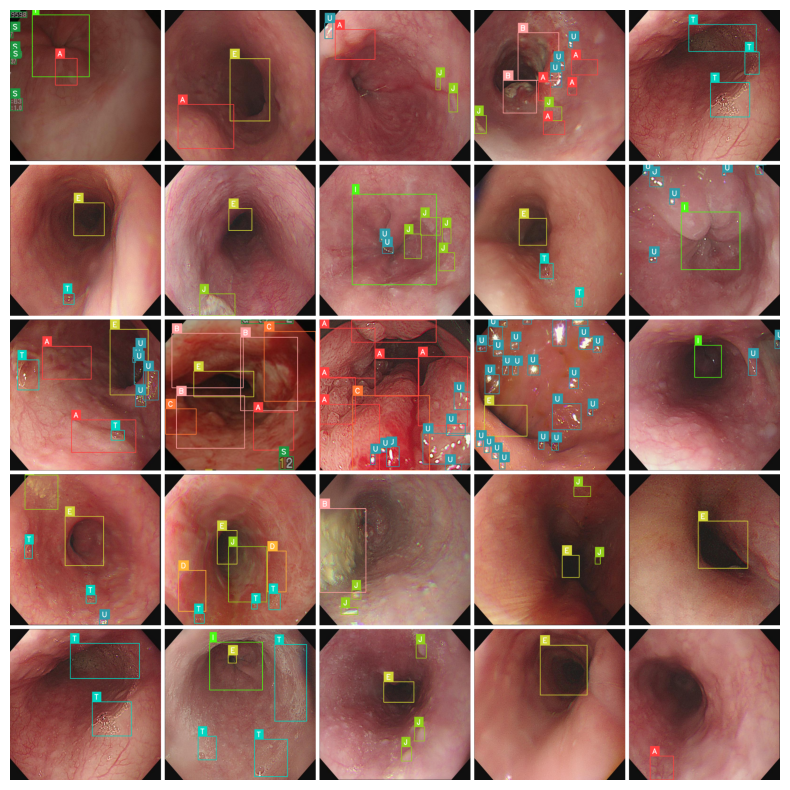

In [10]:
# @title Display dataset sample

GRID_SIZE = 5

def annotate(image, annotations, classes):
    labels = [
        classes[class_id]
        for class_id
        in annotations.class_id
    ]

    bounding_box_annotator = sv.BoundingBoxAnnotator()
    label_annotator = sv.LabelAnnotator(text_scale=1, text_thickness=2)

    annotated_image = image.copy()
    annotated_image = bounding_box_annotator.annotate(annotated_image, annotations)
    annotated_image = label_annotator.annotate(annotated_image, annotations, labels=labels)
    return annotated_image

annotated_images = []
for i in range(GRID_SIZE * GRID_SIZE):
    _, image, annotations = ds_train[i]
    annotated_image = annotate(image, annotations, ds_train.classes)
    annotated_images.append(annotated_image)

grid = sv.create_tiles(
    annotated_images,
    grid_size=(GRID_SIZE, GRID_SIZE),
    single_tile_size=(400, 400),
    tile_padding_color=sv.Color.WHITE,
    tile_margin_color=sv.Color.WHITE
)
sv.plot_image(grid, size=(10, 10))

### Preprocess the data

To finetune a model, you must preprocess the data you plan to use to match precisely the approach used for the pre-trained model. [AutoImageProcessor](https://huggingface.co/docs/transformers/main/en/model_doc/auto#transformers.AutoImageProcessor) takes care of processing image data to create `pixel_values`, `pixel_mask`, and `labels` that a DETR model can train with. The image processor has some attributes that you won't have to worry about:

- `image_mean = [0.485, 0.456, 0.406 ]`
- `image_std = [0.229, 0.224, 0.225]`

These are the mean and standard deviation used to normalize images during the model pre-training. These values are crucial to replicate when doing inference or finetuning a pre-trained image model.

Instantiate the image processor from the same checkpoint as the model you want to finetune.

In [11]:
IMAGE_SIZE = 640

processor = AutoImageProcessor.from_pretrained(
    CHECKPOINT,
    do_resize=True,
    size={"width": IMAGE_SIZE, "height": IMAGE_SIZE},
)

Before passing the images to the `processor`, apply two preprocessing transformations to the dataset:

- Augmenting images
- Reformatting annotations to meet RT-DETR expectations

First, to make sure the model does not overfit on the training data, you can apply image augmentation with any data augmentation library. Here we use [Albumentations](https://albumentations.ai/docs/). This library ensures that transformations affect the image and update the bounding boxes accordingly.

In [12]:
train_augmentation_and_transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Affine(shear={"x": (-10, 10), "y": (-10, 10)}, p=0.5),
        A.Rotate(limit=10, p=0.5)

    ],
    bbox_params=A.BboxParams(
        format="pascal_voc",
        label_fields=["category"],
        clip=True,
        min_area=25
    ),
)

valid_transform = A.Compose(
    [A.NoOp()],
    bbox_params=A.BboxParams(
        format="pascal_voc",
        label_fields=["category"],
        clip=True,
        min_area=1
    ),
)

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


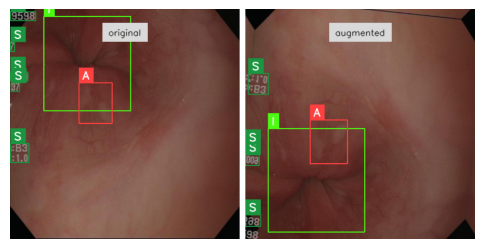

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


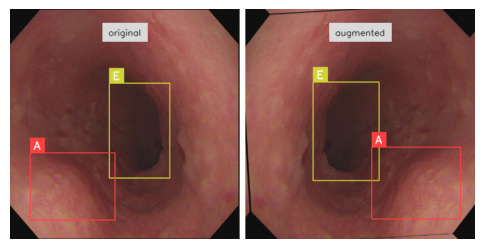

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


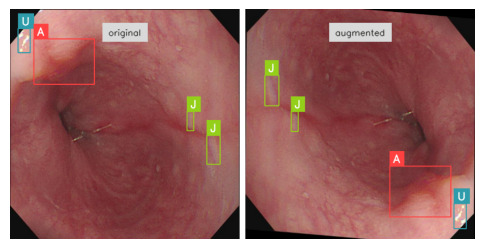

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


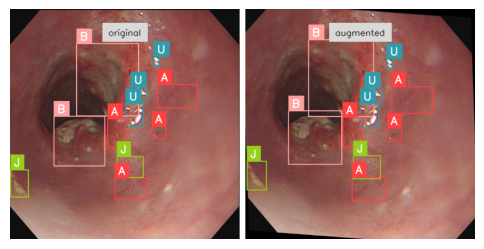

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


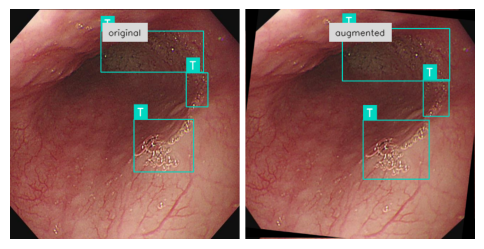

In [13]:
# @title Visualize some augmented images

IMAGE_COUNT = 5

for i in range(IMAGE_COUNT):
    _, image, annotations = ds_train[i]

    output = train_augmentation_and_transform(
        image=image,
        bboxes=annotations.xyxy,
        category=annotations.class_id
    )

    augmented_image = output["image"]
    augmented_annotations = replace(
        annotations,
        xyxy=np.array(output["bboxes"]),
        class_id=np.array(output["category"])
    )

    annotated_images = [
        annotate(image, annotations, ds_train.classes),
        annotate(augmented_image, augmented_annotations, ds_train.classes)
    ]
    grid = sv.create_tiles(
        annotated_images,
        titles=['original', 'augmented'],
        titles_scale=0.5,
        single_tile_size=(400, 400),
        tile_padding_color=sv.Color.WHITE,
        tile_margin_color=sv.Color.WHITE
    )
    sv.plot_image(grid, size=(6, 6))

The `processor` expects the annotations to be in the following format: `{'image_id': int, 'annotations': List[Dict]}`, where each dictionary is a COCO object annotation. Let's add a function to reformat annotations for a single example:

In [14]:
class PyTorchDetectionDataset(Dataset):
    def __init__(self, dataset: sv.DetectionDataset, processor, transform: A.Compose = None):
        self.dataset = dataset
        self.processor = processor
        self.transform = transform

    @staticmethod
    def annotations_as_coco(image_id, categories, boxes):
        annotations = []
        for category, bbox in zip(categories, boxes):
            x1, y1, x2, y2 = bbox
            formatted_annotation = {
                "image_id": image_id,
                "category_id": category,
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "iscrowd": 0,
                "area": (x2 - x1) * (y2 - y1),
            }
            annotations.append(formatted_annotation)

        return {
            "image_id": image_id,
            "annotations": annotations,
        }

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        _, image, annotations = self.dataset[idx]

        # Convert image to RGB numpy array
        image = image[:, :, ::-1]
        boxes = annotations.xyxy
        categories = annotations.class_id

        if self.transform:
            transformed = self.transform(
                image=image,
                bboxes=boxes,
                category=categories
            )
            image = transformed["image"]
            boxes = transformed["bboxes"]
            categories = transformed["category"]


        formatted_annotations = self.annotations_as_coco(
            image_id=idx, categories=categories, boxes=boxes)
        result = self.processor(
            images=image, annotations=formatted_annotations, return_tensors="pt")

        # Image processor expands batch dimension, lets squeeze it
        result = {k: v[0] for k, v in result.items()}

        return result

Now you can combine the image and annotation transformations to use on a batch of examples:

In [15]:
pytorch_dataset_train = PyTorchDetectionDataset(
    ds_train, processor, transform=train_augmentation_and_transform)
pytorch_dataset_valid = PyTorchDetectionDataset(
    ds_valid, processor, transform=valid_transform)
pytorch_dataset_test = PyTorchDetectionDataset(
    ds_test, processor, transform=valid_transform)

pytorch_dataset_train[15]

{'pixel_values': tensor([[[0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588],
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588],
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588]],
 
         [[0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588],
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588],
          [0.0000, 0.0000, 0.0000,  ..., 0.0588, 0.0588, 0.0588]],
 
         [[0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.0588, 0.0588,  ..., 0.0000, 0.0000, 0.0000],
          [0.0588, 0.058

You have successfully augmented the images and prepared their annotations. In the final step, create a custom collate_fn to batch images together.

In [16]:
def collate_fn(batch):
    data = {}
    data["pixel_values"] = torch.stack([x["pixel_values"] for x in batch])
    data["labels"] = [x["labels"] for x in batch]
    return data

## Preparing function to compute mAP

In [17]:
id2label = {id: label for id, label in enumerate(ds_train.classes)}
label2id = {label: id for id, label in enumerate(ds_train.classes)}


@dataclass
class ModelOutput:
    logits: torch.Tensor
    pred_boxes: torch.Tensor


class MAPEvaluator:

    def __init__(self, image_processor, threshold=0.00, id2label=None):
        self.image_processor = image_processor
        self.threshold = threshold
        self.id2label = id2label

    def collect_image_sizes(self, targets):
        """Collect image sizes across the dataset as list of tensors with shape [batch_size, 2]."""
        image_sizes = []
        for batch in targets:
            batch_image_sizes = torch.tensor(np.array([x["size"] for x in batch]))
            image_sizes.append(batch_image_sizes)
        return image_sizes

    def collect_targets(self, targets, image_sizes):
        post_processed_targets = []
        for target_batch, image_size_batch in zip(targets, image_sizes):
            for target, (height, width) in zip(target_batch, image_size_batch):
                boxes = target["boxes"]
                boxes = sv.xcycwh_to_xyxy(boxes)
                boxes = boxes * np.array([width, height, width, height])
                boxes = torch.tensor(boxes)
                labels = torch.tensor(target["class_labels"])
                post_processed_targets.append({"boxes": boxes, "labels": labels})
        return post_processed_targets

    def collect_predictions(self, predictions, image_sizes):
        post_processed_predictions = []
        for batch, target_sizes in zip(predictions, image_sizes):
            batch_logits, batch_boxes = batch[1], batch[2]
            output = ModelOutput(logits=torch.tensor(batch_logits), pred_boxes=torch.tensor(batch_boxes))
            post_processed_output = self.image_processor.post_process_object_detection(
                output, threshold=self.threshold, target_sizes=target_sizes
            )
            post_processed_predictions.extend(post_processed_output)
        return post_processed_predictions

    @torch.no_grad()
    def __call__(self, evaluation_results):

        predictions, targets = evaluation_results.predictions, evaluation_results.label_ids

        image_sizes = self.collect_image_sizes(targets)
        post_processed_targets = self.collect_targets(targets, image_sizes)
        post_processed_predictions = self.collect_predictions(predictions, image_sizes)

        evaluator = MeanAveragePrecision(box_format="xyxy", class_metrics=True)
        evaluator.warn_on_many_detections = False
        evaluator.update(post_processed_predictions, post_processed_targets)

        metrics = evaluator.compute()

        # Replace list of per class metrics with separate metric for each class
        classes = metrics.pop("classes")
        map_per_class = metrics.pop("map_per_class")
        mar_100_per_class = metrics.pop("mar_100_per_class")
        for class_id, class_map, class_mar in zip(classes, map_per_class, mar_100_per_class):
            class_name = id2label[class_id.item()] if id2label is not None else class_id.item()
            metrics[f"map_{class_name}"] = class_map
            metrics[f"mar_100_{class_name}"] = class_mar

        metrics = {k: round(v.item(), 4) for k, v in metrics.items()}

        return metrics

eval_compute_metrics_fn = MAPEvaluator(image_processor=processor, threshold=0.01, id2label=id2label)

## Training the detection model

You have done most of the heavy lifting in the previous sections, so now you are ready to train your model! The images in this dataset are still quite large, even after resizing. This means that finetuning this model will require at least one GPU.

Training involves the following steps:

- Load the model with [`AutoModelForObjectDetection`](https://huggingface.co/docs/transformers/main/en/model_doc/auto#transformers.AutoModelForObjectDetection) using the same checkpoint as in the preprocessing.
- Define your training hyperparameters in [`TrainingArguments`](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.TrainingArguments).
- Pass the training arguments to [`Trainer`](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.Trainer) along with the model, dataset, image processor, and data collator.
- Call [`train()`](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.Trainer.train) to finetune your model.

When loading the model from the same checkpoint that you used for the preprocessing, remember to pass the `label2id` and `id2label` maps that you created earlier from the dataset's metadata. Additionally, we specify `ignore_mismatched_sizes=True` to replace the existing classification head with a new one.

In [18]:
model = AutoModelForObjectDetection.from_pretrained(
    CHECKPOINT,
    id2label=id2label,
    label2id=label2id,
    anchor_image_size=None,
    ignore_mismatched_sizes=True,
)

Some weights of RTDetrForObjectDetection were not initialized from the model checkpoint at PekingU/rtdetr_r50vd_coco_o365 and are newly initialized because the shapes did not match:
- model.decoder.class_embed.0.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([12]) in the model instantiated
- model.decoder.class_embed.0.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([12, 256]) in the model instantiated
- model.decoder.class_embed.1.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([12]) in the model instantiated
- model.decoder.class_embed.1.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([12, 256]) in the model instantiated
- model.decoder.class_embed.2.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([12]) in the model instantiated
- model.decoder.class_embed.2.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([12, 256]) in the model instantiated
- 

In the [`TrainingArguments`](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.TrainingArguments) use `output_dir` to specify where to save your model, then configure hyperparameters as you see fit. For `num_train_epochs=10` training will take about 15 minutes in Google Colab T4 GPU, increase the number of epoch to get better results.

Important notes:

- Do not remove unused columns because this will drop the image column. Without the image column, you can't create `pixel_values`. For this reason, set `remove_unused_columns` to `False`.
- Set `eval_do_concat_batches=False` to get proper evaluation results. Images have different number of target boxes, if batches are concatenated we will not be able to determine which boxes belongs to particular image.

In [19]:
# training_args = TrainingArguments(
#     output_dir=f"{dataset.name.replace(' ', '-')}-finetune",
#     num_train_epochs=600,
#     max_grad_norm=0.1,
#     learning_rate=5e-5,
#     warmup_steps=300,
#     per_device_train_batch_size=16,
#     dataloader_num_workers=2,
#     metric_for_best_model="eval_map",
#     greater_is_better=True,
#     load_best_model_at_end=True,
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     save_total_limit=2,
#     remove_unused_columns=False,
#     eval_do_concat_batches=False,
# )
training_args = TrainingArguments(
    output_dir=f"{dataset.name.replace(' ', '-')}-finetune",
    num_train_epochs=600,
    max_grad_norm=0.1,
    learning_rate=4e-5,  #  decreased learning rate
    warmup_steps=300,
    per_device_train_batch_size=16,
    dataloader_num_workers=4,
    metric_for_best_model="eval_map",
    greater_is_better=True,
    load_best_model_at_end=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    remove_unused_columns=False,
    eval_do_concat_batches=False,
    lr_scheduler_type='cosine',  # Use cosine annealing
    evaluation_strategy='epoch',
)

`evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead


Finally, bring everything together, and call [`train()`](https://huggingface.co/docs/transformers/main/en/main_classes/trainer#transformers.Trainer.train):

In [20]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=pytorch_dataset_train,
    eval_dataset=pytorch_dataset_valid,
    tokenizer=processor,
    data_collator=collate_fn,
    compute_metrics=eval_compute_metrics_fn,
)

trainer.train()

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


Epoch,Training Loss,Validation Loss,Map,Map 50,Map 75,Map Small,Map Medium,Map Large,Mar 1,Mar 10,Mar 100,Mar Small,Mar Medium,Mar Large,Map Lesion-xa8r,Mar 100 Lesion-xa8r,Map A,Mar 100 A,Map B,Mar 100 B,Map C,Mar 100 C,Map D,Mar 100 D,Map E,Mar 100 E,Map I,Mar 100 I,Map J,Mar 100 J,Map K,Mar 100 K,Map S,Mar 100 S,Map T,Mar 100 T,Map U,Mar 100 U
1,No log,31.000614,0.005600,0.013400,0.004400,0.008200,0.009700,0.008200,0.033700,0.114800,0.147400,0.084500,0.078900,0.188300,-1.000000,-1.000000,0.000000,0.010000,0.001000,0.091100,0.000300,0.125300,0.000000,0.005900,0.022800,0.248300,0.000600,0.098300,0.000900,0.161300,0.000600,0.412500,0.000300,0.035800,0.003200,0.191100,0.032100,0.241400
2,No log,20.623005,0.038400,0.084900,0.033900,0.032000,0.048500,0.024100,0.055800,0.168300,0.229500,0.191200,0.223700,0.190200,-1.000000,-1.000000,0.002400,0.068900,0.000300,0.050000,0.002500,0.272000,0.000000,0.047100,0.135400,0.394000,0.000500,0.112100,0.008200,0.221500,0.000100,0.037500,0.080100,0.423200,0.030100,0.360800,0.162900,0.537400
3,No log,16.854357,0.103600,0.190900,0.103500,0.120600,0.111600,0.097500,0.106200,0.292700,0.382100,0.340200,0.318500,0.401100,-1.000000,-1.000000,0.011600,0.219100,0.002800,0.219600,0.014500,0.442700,0.000000,0.023500,0.199400,0.487300,0.011500,0.413800,0.046200,0.299600,0.001100,0.262500,0.507100,0.789500,0.123300,0.480400,0.221600,0.565200
4,No log,15.735090,0.138300,0.244900,0.143400,0.165400,0.143500,0.145700,0.126600,0.348700,0.435200,0.325700,0.365000,0.472900,-1.000000,-1.000000,0.013900,0.236300,0.017800,0.373200,0.081000,0.460000,0.000100,0.164700,0.214200,0.506000,0.010400,0.325900,0.056100,0.357900,0.005200,0.450000,0.694000,0.843200,0.176200,0.516800,0.252400,0.553900
5,No log,14.801107,0.156300,0.288300,0.151100,0.168300,0.150800,0.180800,0.145500,0.377600,0.446600,0.293600,0.355300,0.485500,-1.000000,-1.000000,0.032700,0.258200,0.021800,0.385700,0.145800,0.498700,0.003300,0.223500,0.207400,0.482800,0.046600,0.424100,0.051900,0.356700,0.035900,0.412500,0.711800,0.826300,0.209600,0.520600,0.252700,0.523600
6,30.857400,14.506785,0.164900,0.295800,0.164800,0.179100,0.158800,0.194500,0.136400,0.377000,0.468600,0.319200,0.374400,0.511100,-1.000000,-1.000000,0.033500,0.251800,0.029500,0.412500,0.137300,0.521300,0.021200,0.158800,0.173400,0.528500,0.038900,0.493100,0.066100,0.385100,0.081500,0.512500,0.772300,0.852600,0.204900,0.507900,0.255000,0.530100
7,30.857400,14.247681,0.183400,0.337200,0.180100,0.185100,0.171100,0.220400,0.153200,0.389500,0.463300,0.356500,0.358900,0.499100,-1.000000,-1.000000,0.053200,0.322300,0.014100,0.328600,0.198700,0.548000,0.010600,0.188200,0.202900,0.465900,0.090500,0.519000,0.061400,0.348700,0.112100,0.475000,0.783500,0.849500,0.219700,0.500600,0.270900,0.550100
8,30.857400,14.315938,0.182300,0.335200,0.176800,0.182100,0.192500,0.211300,0.162900,0.400300,0.478600,0.346600,0.354800,0.526200,-1.000000,-1.000000,0.050600,0.304000,0.049400,0.400000,0.226300,0.582700,0.004000,0.176500,0.194000,0.526600,0.077400,0.506900,0.061400,0.356300,0.099200,0.550000,0.775800,0.853700,0.213700,0.483500,0.253900,0.524800
9,30.857400,14.097181,0.203300,0.366800,0.197800,0.186100,0.179500,0.236700,0.184500,0.415200,0.483300,0.311200,0.355000,0.535300,-1.000000,-1.000000,0.044800,0.290800,0.069800,0.444600,0.261000,0.553300,0.002900,0.170600,0.219500,0.477200,0.151700,0.517200,0.068200,0.390000,0.119000,0.550000,0.800100,0.854700,0.222000,0.520900,0.276900,0.547200
10,30.857400,14.315981,0.207300,0.372300,0.206100,0.193100,0.172700,0.240800,0.197200,0.395300,0.461500,0.410500,0.340400,0.509400,-1.000000,-1.000000,0.044600,0.238600,0.078600,0.432100,0.259700,0.532000,0.002400,0.094100,0.195300,0.529600,0.190500,0.544800,0.057300,0.341400,0.173300,0.450000,0.805100,0.850500,0.223100,0.535100,0.250800,0.527700


os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
os.fork() was called. os.fo

Epoch,Training Loss,Validation Loss,Map,Map 50,Map 75,Map Small,Map Medium,Map Large,Mar 1,Mar 10,Mar 100,Mar Small,Mar Medium,Mar Large,Map Lesion-xa8r,Mar 100 Lesion-xa8r,Map A,Mar 100 A,Map B,Mar 100 B,Map C,Mar 100 C,Map D,Mar 100 D,Map E,Mar 100 E,Map I,Mar 100 I,Map J,Mar 100 J,Map K,Mar 100 K,Map S,Mar 100 S,Map T,Mar 100 T,Map U,Mar 100 U
1,No log,31.000614,0.005600,0.013400,0.004400,0.008200,0.009700,0.008200,0.033700,0.114800,0.147400,0.084500,0.078900,0.188300,-1.000000,-1.000000,0.000000,0.010000,0.001000,0.091100,0.000300,0.125300,0.000000,0.005900,0.022800,0.248300,0.000600,0.098300,0.000900,0.161300,0.000600,0.412500,0.000300,0.035800,0.003200,0.191100,0.032100,0.241400
2,No log,20.623005,0.038400,0.084900,0.033900,0.032000,0.048500,0.024100,0.055800,0.168300,0.229500,0.191200,0.223700,0.190200,-1.000000,-1.000000,0.002400,0.068900,0.000300,0.050000,0.002500,0.272000,0.000000,0.047100,0.135400,0.394000,0.000500,0.112100,0.008200,0.221500,0.000100,0.037500,0.080100,0.423200,0.030100,0.360800,0.162900,0.537400
3,No log,16.854357,0.103600,0.190900,0.103500,0.120600,0.111600,0.097500,0.106200,0.292700,0.382100,0.340200,0.318500,0.401100,-1.000000,-1.000000,0.011600,0.219100,0.002800,0.219600,0.014500,0.442700,0.000000,0.023500,0.199400,0.487300,0.011500,0.413800,0.046200,0.299600,0.001100,0.262500,0.507100,0.789500,0.123300,0.480400,0.221600,0.565200
4,No log,15.735090,0.138300,0.244900,0.143400,0.165400,0.143500,0.145700,0.126600,0.348700,0.435200,0.325700,0.365000,0.472900,-1.000000,-1.000000,0.013900,0.236300,0.017800,0.373200,0.081000,0.460000,0.000100,0.164700,0.214200,0.506000,0.010400,0.325900,0.056100,0.357900,0.005200,0.450000,0.694000,0.843200,0.176200,0.516800,0.252400,0.553900
5,No log,14.801107,0.156300,0.288300,0.151100,0.168300,0.150800,0.180800,0.145500,0.377600,0.446600,0.293600,0.355300,0.485500,-1.000000,-1.000000,0.032700,0.258200,0.021800,0.385700,0.145800,0.498700,0.003300,0.223500,0.207400,0.482800,0.046600,0.424100,0.051900,0.356700,0.035900,0.412500,0.711800,0.826300,0.209600,0.520600,0.252700,0.523600
6,30.857400,14.506785,0.164900,0.295800,0.164800,0.179100,0.158800,0.194500,0.136400,0.377000,0.468600,0.319200,0.374400,0.511100,-1.000000,-1.000000,0.033500,0.251800,0.029500,0.412500,0.137300,0.521300,0.021200,0.158800,0.173400,0.528500,0.038900,0.493100,0.066100,0.385100,0.081500,0.512500,0.772300,0.852600,0.204900,0.507900,0.255000,0.530100
7,30.857400,14.247681,0.183400,0.337200,0.180100,0.185100,0.171100,0.220400,0.153200,0.389500,0.463300,0.356500,0.358900,0.499100,-1.000000,-1.000000,0.053200,0.322300,0.014100,0.328600,0.198700,0.548000,0.010600,0.188200,0.202900,0.465900,0.090500,0.519000,0.061400,0.348700,0.112100,0.475000,0.783500,0.849500,0.219700,0.500600,0.270900,0.550100
8,30.857400,14.315938,0.182300,0.335200,0.176800,0.182100,0.192500,0.211300,0.162900,0.400300,0.478600,0.346600,0.354800,0.526200,-1.000000,-1.000000,0.050600,0.304000,0.049400,0.400000,0.226300,0.582700,0.004000,0.176500,0.194000,0.526600,0.077400,0.506900,0.061400,0.356300,0.099200,0.550000,0.775800,0.853700,0.213700,0.483500,0.253900,0.524800
9,30.857400,14.097181,0.203300,0.366800,0.197800,0.186100,0.179500,0.236700,0.184500,0.415200,0.483300,0.311200,0.355000,0.535300,-1.000000,-1.000000,0.044800,0.290800,0.069800,0.444600,0.261000,0.553300,0.002900,0.170600,0.219500,0.477200,0.151700,0.517200,0.068200,0.390000,0.119000,0.550000,0.800100,0.854700,0.222000,0.520900,0.276900,0.547200
10,30.857400,14.315981,0.207300,0.372300,0.206100,0.193100,0.172700,0.240800,0.197200,0.395300,0.461500,0.410500,0.340400,0.509400,-1.000000,-1.000000,0.044600,0.238600,0.078600,0.432100,0.259700,0.532000,0.002400,0.094100,0.195300,0.529600,0.190500,0.544800,0.057300,0.341400,0.173300,0.450000,0.805100,0.850500,0.223100,0.535100,0.250800,0.527700


os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
There were missing keys in the checkpoint model loaded: ['class_embed.0.weight', 'class_embed.0.bias', 'class_embed.1.weight', 'class_embed.1.bias', 'class_embed.2.weight', 'class_embed.2.bias', 'class_embed.3.weight', 'class_embed.3.bias', 'class_embed.4.weight', 'class_embed.4.bias', 'class_embed.5.weight', 'class_embed.5.bias', 'bbox_embed.0.layers.0.weight', 'bbox_embed.0.layers.0.bias', 'bbox_embed.0.layers.1.weight', 'bbox_embed.0.layers.1.bias', 'bbox_embed.0.layers.2.weight', 'bbox_embed.0.layers.2.bias', 'bbox_embed.1.layers.0.weight', 'bbox_embed.1.layers.0.bias', 'bbox_embed.1.layers.1.weight', 'bbox_embed.1.layers.1.bias', 'bbox_embed.1.layers.2.weight', 'bbox_embed.1.layers.2.bias', 'bbox_embed.2.layers.0.weight', 'bbox_embed.2.layers.0.bias', 'bbox_embed.2.layers.1.weight', 'bbox_embed.2.layers.1.bias', 'bbox_embed.2.layers.2.weight', 

TrainOutput(global_step=54600, training_loss=7.31000238215967, metrics={'train_runtime': 39943.375, 'train_samples_per_second': 21.691, 'train_steps_per_second': 1.367, 'total_flos': 2.7306735638151168e+20, 'train_loss': 7.31000238215967, 'epoch': 600.0})

In [21]:
# @title Collect predictions

targets = []
predictions = []

for i in range(len(ds_test)):
    path, sourece_image, annotations = ds_test[i]

    image = Image.open(path)
    inputs = processor(image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    w, h = image.size
    results = processor.post_process_object_detection(
        outputs, target_sizes=[(h, w)], threshold=0.3)

    detections = sv.Detections.from_transformers(results[0])

    targets.append(annotations)
    predictions.append(detections)

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!zip -r /content/Kaohsiung_nonAug_NBI-finetune.zip /content/Kaohsiung_non_Aug-finetune
files.download("/content/Kaohsiung_non_Aug-finetune.zip")

  adding: content/Kaohsiung_non_Aug-finetune/ (stored 0%)
  adding: content/Kaohsiung_non_Aug-finetune/runs/ (stored 0%)
  adding: content/Kaohsiung_non_Aug-finetune/runs/Jul29_18-29-15_78754ecf73ce/ (stored 0%)
  adding: content/Kaohsiung_non_Aug-finetune/runs/Jul29_18-29-15_78754ecf73ce/events.out.tfevents.1722277763.78754ecf73ce.5704.0 (deflated 71%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/ (stored 0%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/scheduler.pt (deflated 56%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/preprocessor_config.json (deflated 46%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/optimizer.pt (deflated 8%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/trainer_state.json (deflated 87%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/rng_state.pth (deflated 25%)
  adding: content/Kaohsiung_non_Aug-finetune/checkpoint-54600/training_args.bin (deflated 51%)
  addi

In [23]:
# @title Calculate mAP
mean_average_precision = sv.MeanAveragePrecision.from_detections(
    predictions=predictions,
    targets=targets,
)

print(f"map50_95: {mean_average_precision.map50_95:.2f}")
print(f"map50: {mean_average_precision.map50:.2f}")
print(f"map75: {mean_average_precision.map75:.2f}")

map50_95: 0.46
map50: 0.68
map75: 0.49


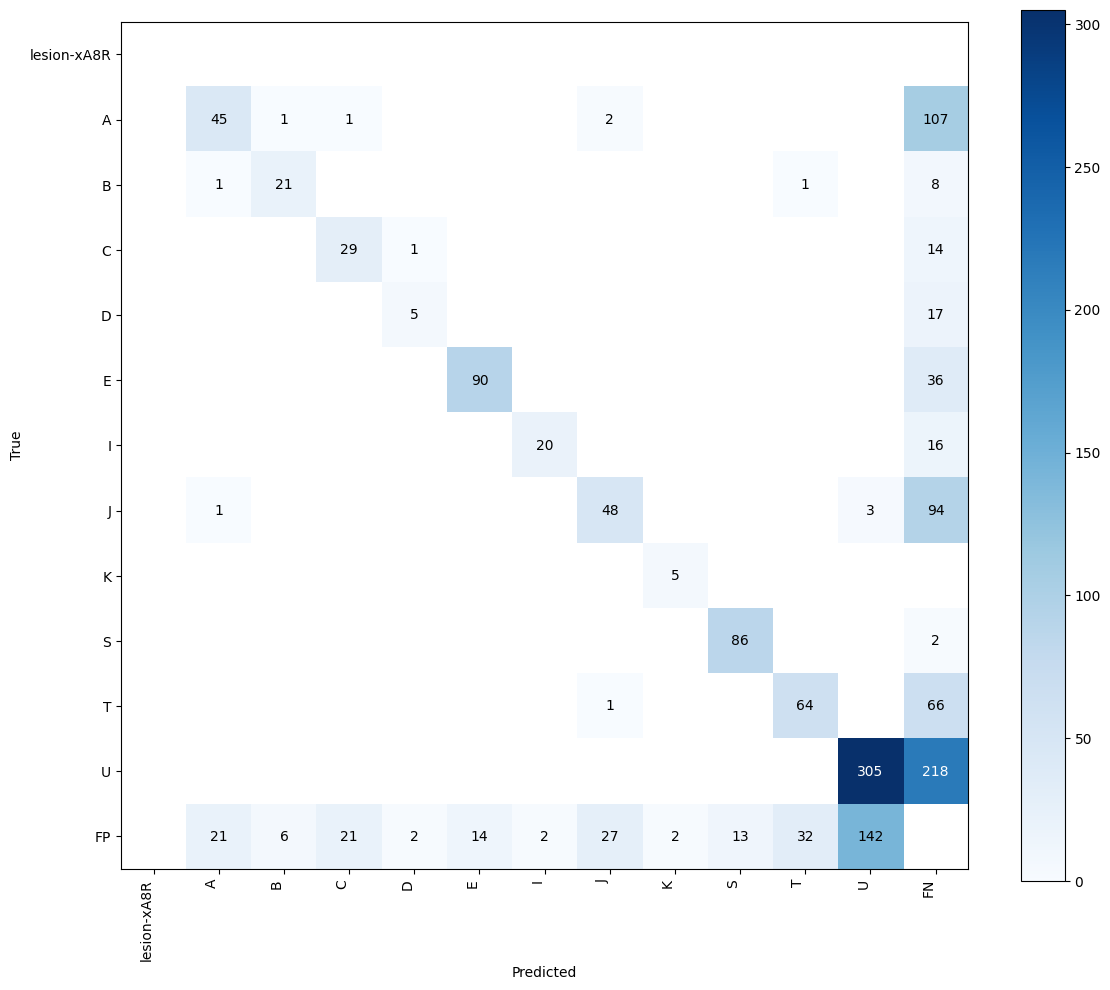

In [24]:
# @title Calculate Confusion Matrix
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=ds_test.classes
)

_ = confusion_matrix.plot()

In [25]:
model.save_pretrained("/content/rt-detr/")
processor.save_pretrained("/content/rt-detr/")

['/content/rt-detr/preprocessor_config.json']

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


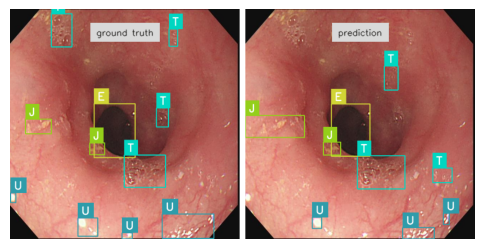

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


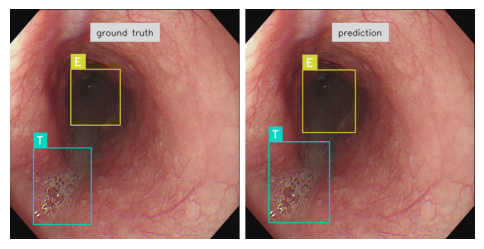

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


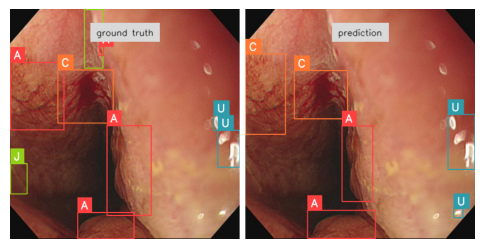

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


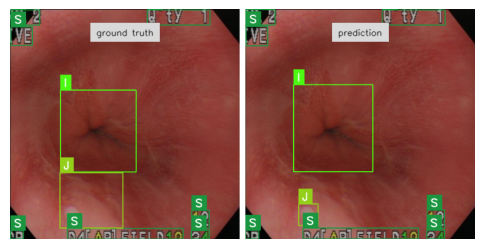

BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.
BoundingBoxAnnotator is deprecated: `BoundingBoxAnnotator` is deprecated and has been renamed to `BoxAnnotator`. `BoundingBoxAnnotator` will be removed in supervision-0.26.0.


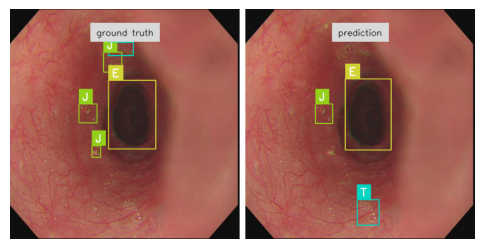

In [26]:
IMAGE_COUNT = 5

for i in range(IMAGE_COUNT):
    path, sourece_image, annotations = ds_test[i]

    image = Image.open(path)
    inputs = processor(image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    w, h = image.size
    results = processor.post_process_object_detection(
        outputs, target_sizes=[(h, w)], threshold=0.3)

    detections = sv.Detections.from_transformers(results[0]).with_nms(threshold=0.1)

    annotated_images = [
        annotate(sourece_image, annotations, ds_train.classes),
        annotate(sourece_image, detections, ds_train.classes)
    ]
    grid = sv.create_tiles(
        annotated_images,
        titles=['ground truth', 'prediction'],
        titles_scale=0.5,
        single_tile_size=(400, 400),
        tile_padding_color=sv.Color.WHITE,
        tile_margin_color=sv.Color.WHITE
    )
    sv.plot_image(grid, size=(6, 6))

map50_95: 0.46
map50: 0.68
map75: 0.49

Precision and Recall for each class:
lesion-xA8R: Precision: 0.00, Recall: 0.00
A: Precision: 0.66, Recall: 0.29
B: Precision: 0.75, Recall: 0.68
C: Precision: 0.57, Recall: 0.66
D: Precision: 0.62, Recall: 0.23
E: Precision: 0.87, Recall: 0.71
I: Precision: 0.91, Recall: 0.56
J: Precision: 0.62, Recall: 0.33
K: Precision: 0.71, Recall: 1.00
S: Precision: 0.87, Recall: 0.98
T: Precision: 0.66, Recall: 0.49
U: Precision: 0.68, Recall: 0.58


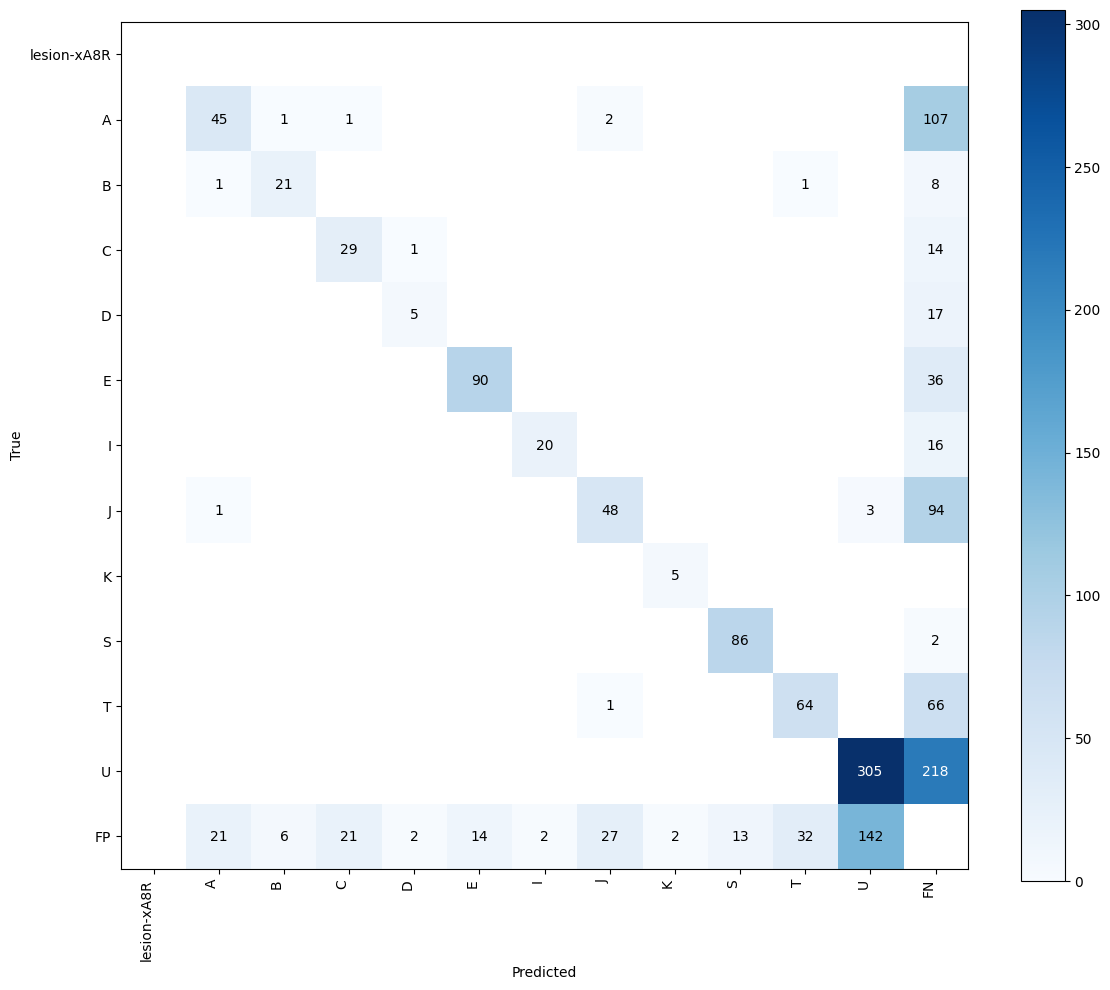

In [27]:

# Calculate mAP
mean_average_precision = sv.MeanAveragePrecision.from_detections(
    predictions=predictions,
    targets=targets,
)

print(f"map50_95: {mean_average_precision.map50_95:.2f}")
print(f"map50: {mean_average_precision.map50:.2f}")
print(f"map75: {mean_average_precision.map75:.2f}")

# Calculate Confusion Matrix
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=ds_test.classes
)

_ = confusion_matrix.plot()

# Extracting the confusion matrix
cm = confusion_matrix.matrix
class_names = ds_test.classes

# Calculating precision and recall for each class
precision = {}
recall = {}

for idx, class_name in enumerate(class_names):
    tp = cm[idx, idx]
    fp = cm[:, idx].sum() - tp
    fn = cm[idx, :].sum() - tp

    precision[class_name] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall[class_name] = tp / (tp + fn) if (tp + fn) > 0 else 0.0

# Printing precision and recall for each class
print("\nPrecision and Recall for each class:")
for class_name in class_names:
    print(f"{class_name}: Precision: {precision[class_name]:.2f}, Recall: {recall[class_name]:.2f}")


In [28]:
!zip -r /content/rt-detr.zip /content/rt-detr
from google.colab import files
files.download("/content/rt-detr.zip")

  adding: content/rt-detr/ (stored 0%)
  adding: content/rt-detr/preprocessor_config.json (deflated 46%)
  adding: content/rt-detr/config.json (deflated 61%)
  adding: content/rt-detr/model.safetensors (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# @title Calculate mAP
mean_average_precision = sv.MeanAveragePrecision.from_detections(
    predictions=predictions,
    targets=targets,
)

print(f"map50_95: {mean_average_precision.map50_95:.2f}")
print(f"map50: {mean_average_precision.map50:.2f}")
print(f"map75: {mean_average_precision.map75:.2f}")

In [ ]:
# @title Calculate Confusion Matrix
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=ds_test.classes
)

_ = confusion_matrix.plot()

In [ ]:
model.save_pretrained("/content/rt-detr/")
processor.save_pretrained("/content/rt-detr/")

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

In [ ]:
!zip -r /content/Kaohsiung_nonAug_NBI-finetune.zip /content/Kaohsiung_nonAug_NBI-finetune

In [ ]:
from google.colab import files
files.download("/content/Kaohsiung_nonAug_NBI-finetune.zip")

In [ ]:
IMAGE_COUNT = 5

for i in range(IMAGE_COUNT):
    path, sourece_image, annotations = ds_test[i]

    image = Image.open(path)
    inputs = processor(image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    w, h = image.size
    results = processor.post_process_object_detection(
        outputs, target_sizes=[(h, w)], threshold=0.3)

    detections = sv.Detections.from_transformers(results[0]).with_nms(threshold=0.1)

    annotated_images = [
        annotate(sourece_image, annotations, ds_train.classes),
        annotate(sourece_image, detections, ds_train.classes)
    ]
    grid = sv.create_tiles(
        annotated_images,
        titles=['ground truth', 'prediction'],
        titles_scale=0.5,
        single_tile_size=(400, 400),
        tile_padding_color=sv.Color.WHITE,
        tile_margin_color=sv.Color.WHITE
    )
    sv.plot_image(grid, size=(6, 6))

In [ ]:

# Calculate mAP
mean_average_precision = sv.MeanAveragePrecision.from_detections(
    predictions=predictions,
    targets=targets,
)

print(f"map50_95: {mean_average_precision.map50_95:.2f}")
print(f"map50: {mean_average_precision.map50:.2f}")
print(f"map75: {mean_average_precision.map75:.2f}")

# Calculate Confusion Matrix
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=ds_test.classes
)

_ = confusion_matrix.plot()

# Extracting the confusion matrix
cm = confusion_matrix.matrix
class_names = ds_test.classes

# Calculating precision and recall for each class
precision = {}
recall = {}

for idx, class_name in enumerate(class_names):
    tp = cm[idx, idx]
    fp = cm[:, idx].sum() - tp
    fn = cm[idx, :].sum() - tp

    precision[class_name] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall[class_name] = tp / (tp + fn) if (tp + fn) > 0 else 0.0

# Printing precision and recall for each class
print("\nPrecision and Recall for each class:")
for class_name in class_names:
    print(f"{class_name}: Precision: {precision[class_name]:.2f}, Recall: {recall[class_name]:.2f}")


In [ ]:
!zip -r /content/rt-detr.zip /content/rt-detr

In [ ]:
from google.colab import files
files.download("/content/rt-detr.zip")

